# Plant Disease Classification using CNN, LSTM, RNN,Bi-LSTM and GNN

This notebook adapts the uploaded Brain Tumor MRI workflow to the Kaggle **Plant Disease** image dataset (`emmarex/plantdisease`).

**Dataset note:** this Kaggle dataset is commonly distributed as a `PlantVillage` directory containing one folder per disease/healthy class. It does not provide the same `Training/Testing` folder layout as the MRI dataset, so this notebook creates a reproducible stratified 80/20 train/test split. The notebook discovers the image-folder directory automatically.

Run in Kaggle with the dataset added to the notebook. The reported metrics and plots are generated by training; no accuracy values are hard-coded.

Importing Libraries


In [1]:
# 1. Imports, device, dataset discovery and stratified split
import os, random, copy, numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, TensorDataset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Find the PlantVillage folder (or a directory whose immediate children are class folders).
search_roots = ["/kaggle/input", "/content"]
dataset_dir = None
for search_root in search_roots:
    if os.path.exists(search_root):
        for root, dirs, files in os.walk(search_root):
            class_dirs = [d for d in dirs if not d.startswith(".")]
            if len(class_dirs) >= 2 and ("plantvillage" in root.lower() or "plant disease" in root.lower()):
                dataset_dir = root
                break
        if dataset_dir:
            break

if dataset_dir is None:
    raise FileNotFoundError(
        "Could not automatically locate the PlantVillage class-folder directory. "
        "Set dataset_dir manually to the folder containing one subfolder per class."
    )

print("Dataset directory:", dataset_dir)

# Preserve RGB: leaf color and lesion appearance are useful disease features.
image_size = 128
transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])
full_data = datasets.ImageFolder(root=dataset_dir, transform=transform)
class_names = full_data.classes
num_classes = len(class_names)
print("Number of images:", len(full_data))
print("Number of classes:", num_classes)
print("Classes:", class_names)

targets = np.array(full_data.targets)
indices = np.arange(len(full_data))
train_idx, test_idx = train_test_split(
    indices, test_size=0.20, random_state=SEED, stratify=targets
)
train_data = Subset(full_data, train_idx)
test_data = Subset(full_data, test_idx)

batch_size = 32
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())
print(f"Training images: {len(train_data)} | Testing images: {len(test_data)}")

Using device: cuda
Dataset directory: /kaggle/input/datasets/emmarex/plantdisease/PlantVillage
Number of images: 20638
Number of classes: 15
Classes: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
Training images: 16510 | Testing images: 4128


training and evaluation functions

In [2]:
# 2. Shared training and evaluation functions
def train_model(model, train_loader, test_loader, epochs=10, lr=0.001, graph_model=False):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"loss": [], "train_acc": [], "test_acc": []}

    for epoch in range(epochs):
        model.train()
        total_loss, correct, total = 0.0, 0, 0
        for batch in train_loader:
            if graph_model:
                features, adjacency, labels = batch
                features, adjacency, labels = features.to(device), adjacency.to(device), labels.to(device)
                outputs = model(features, adjacency)
            else:
                images, labels = batch
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)

            optimizer.zero_grad()
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        train_loss = total_loss / total
        train_acc = correct / total
        test_acc, _, _ = evaluate_model(model, test_loader, graph_model=graph_model)
        history["loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)
        print(f"Epoch [{epoch+1}/{epochs}] Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}% | Test Acc: {test_acc*100:.2f}%")
    return model, history

def evaluate_model(model, loader, graph_model=False):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            if graph_model:
                features, adjacency, labels = batch
                outputs = model(features.to(device), adjacency.to(device))
            else:
                images, labels = batch
                outputs = model(images.to(device))
            all_preds.extend(outputs.argmax(1).cpu().numpy())
            all_labels.extend(labels.numpy())
    return accuracy_score(all_labels, all_preds), np.array(all_preds), np.array(all_labels)

def show_evaluation(name, model, history, loader, graph_model=False):
    acc, preds, labels = evaluate_model(model, loader, graph_model)
    print(f"\n{name} Test Accuracy: {acc*100:.2f}%")
    print(classification_report(labels, preds, labels=np.arange(num_classes),
                                target_names=class_names, zero_division=0))
    cm = confusion_matrix(labels, preds, labels=np.arange(num_classes))
    fig, ax = plt.subplots(1, 2, figsize=(18, 6))
    ax[0].plot(history["loss"], marker="o")
    ax[0].set_title(f"{name} Training Loss")
    ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Cross-Entropy Loss"); ax[0].grid(alpha=.3)
    sns.heatmap(cm, cmap="Blues", ax=ax[1], cbar=True)
    ax[1].set_title(f"{name} Test Confusion Matrix")
    ax[1].set_xlabel("Predicted class index"); ax[1].set_ylabel("Actual class index")
    plt.tight_layout(); plt.show()
    return acc, preds, labels

** CNN model**

Epoch [1/10] Loss: 1.4032 | Train Acc: 53.53% | Test Acc: 77.42%
Epoch [2/10] Loss: 0.6855 | Train Acc: 77.53% | Test Acc: 86.00%
Epoch [3/10] Loss: 0.4783 | Train Acc: 83.96% | Test Acc: 89.46%
Epoch [4/10] Loss: 0.3734 | Train Acc: 87.60% | Test Acc: 91.18%
Epoch [5/10] Loss: 0.3070 | Train Acc: 89.70% | Test Acc: 93.27%
Epoch [6/10] Loss: 0.2535 | Train Acc: 91.36% | Test Acc: 93.24%
Epoch [7/10] Loss: 0.2154 | Train Acc: 92.76% | Test Acc: 94.21%
Epoch [8/10] Loss: 0.1945 | Train Acc: 93.45% | Test Acc: 93.80%
Epoch [9/10] Loss: 0.1667 | Train Acc: 94.31% | Test Acc: 95.11%
Epoch [10/10] Loss: 0.1393 | Train Acc: 95.40% | Test Acc: 95.18%

CNN Test Accuracy: 95.18%
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.94      0.95      0.94       199
                     Pepper__bell___healthy       0.97      0.98      0.98       296
                      Potato___Early_blight       0.95      0.99  

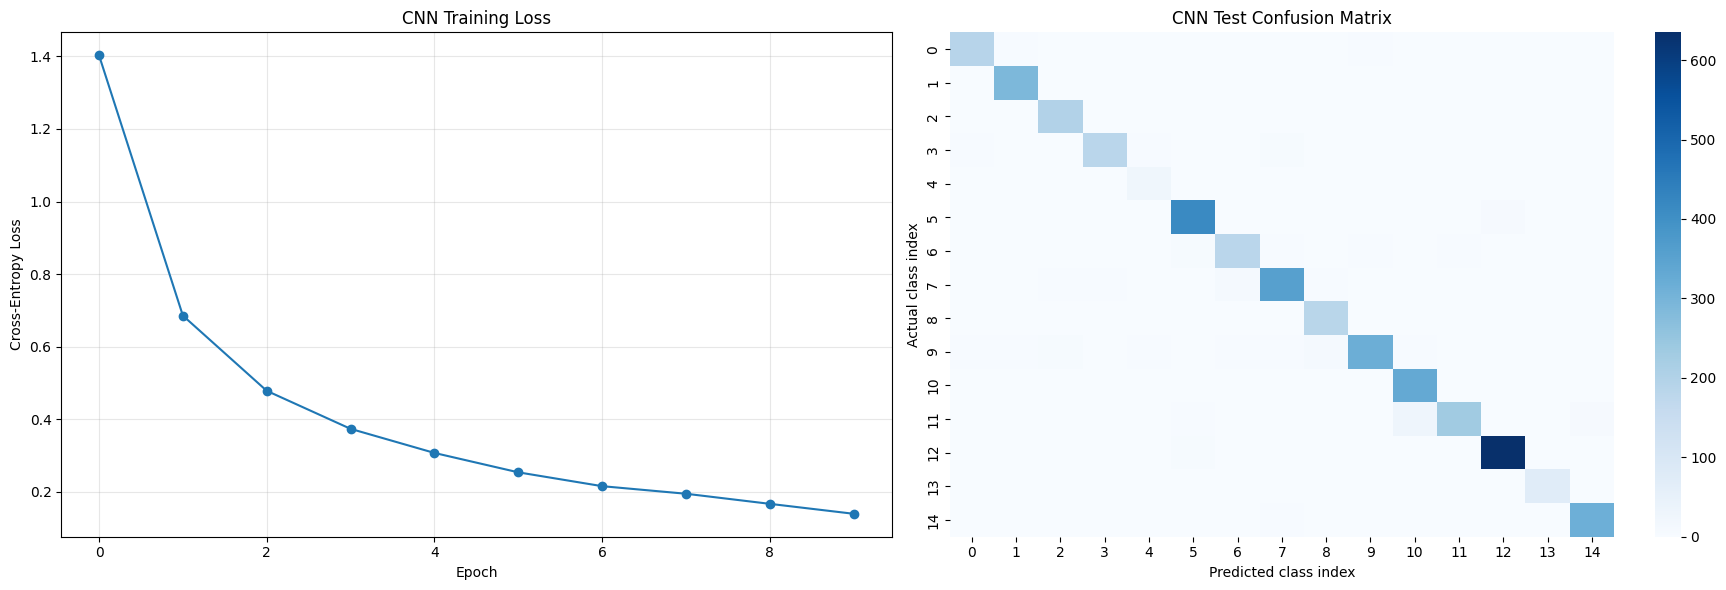

In [3]:
# 3. CNN model
class PlantDiseaseCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(128*4*4, 256), nn.ReLU(),
            nn.Dropout(0.4), nn.Linear(256, num_classes)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

cnn_model = PlantDiseaseCNN(num_classes)
cnn_model, cnn_history = train_model(cnn_model, train_loader, test_loader, epochs=10)
cnn_acc, cnn_preds, y_true = show_evaluation("CNN", cnn_model, cnn_history, test_loader)

** LSTM model**

Epoch [1/10] Loss: 1.8948 | Train Acc: 38.84% | Test Acc: 49.25%
Epoch [2/10] Loss: 1.3781 | Train Acc: 54.75% | Test Acc: 61.24%
Epoch [3/10] Loss: 1.1323 | Train Acc: 63.13% | Test Acc: 68.00%
Epoch [4/10] Loss: 0.9696 | Train Acc: 68.38% | Test Acc: 72.09%
Epoch [5/10] Loss: 0.8510 | Train Acc: 72.10% | Test Acc: 74.66%
Epoch [6/10] Loss: 0.7406 | Train Acc: 76.04% | Test Acc: 77.28%
Epoch [7/10] Loss: 0.6628 | Train Acc: 78.34% | Test Acc: 78.75%
Epoch [8/10] Loss: 0.6001 | Train Acc: 80.49% | Test Acc: 80.79%
Epoch [9/10] Loss: 0.5586 | Train Acc: 81.99% | Test Acc: 82.27%
Epoch [10/10] Loss: 0.5097 | Train Acc: 83.33% | Test Acc: 80.50%

LSTM Test Accuracy: 80.50%
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.72      0.60      0.65       199
                     Pepper__bell___healthy       0.81      0.93      0.86       296
                      Potato___Early_blight       0.82      0.90 

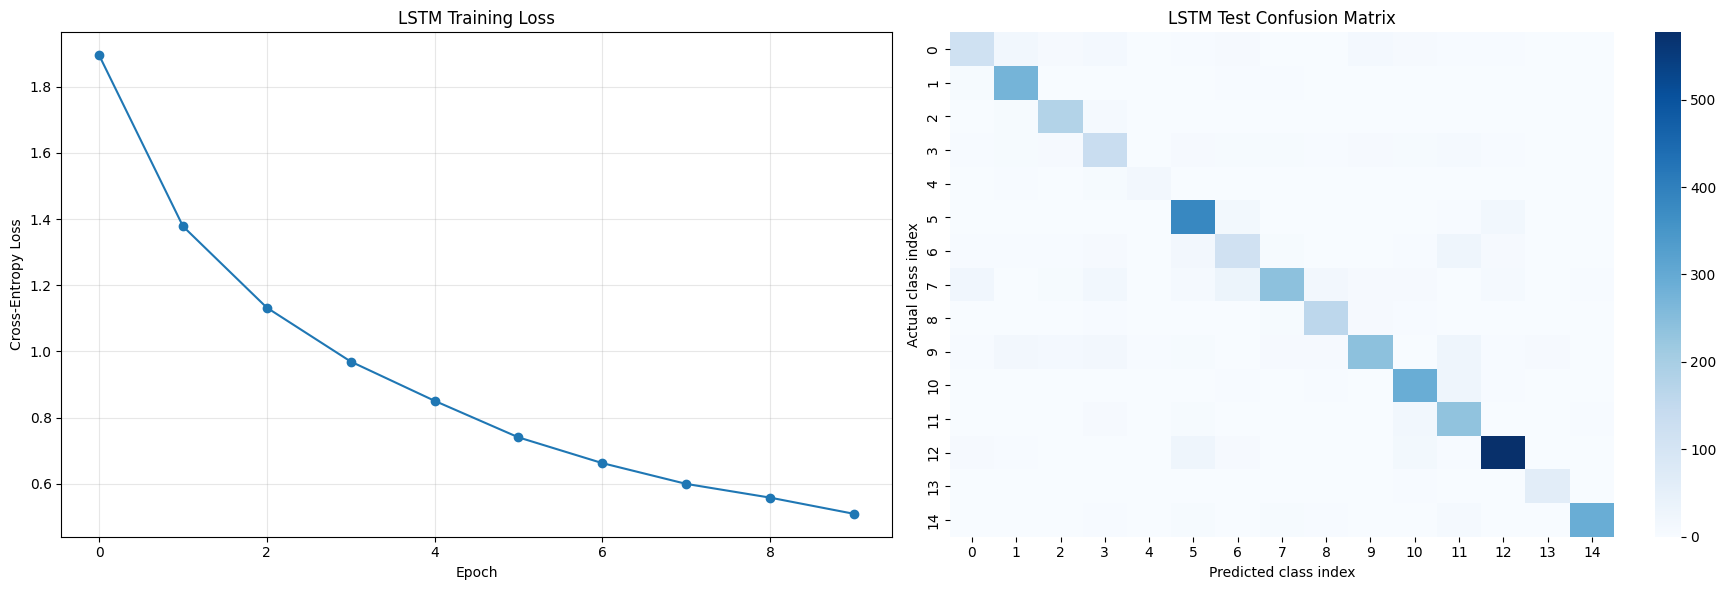

In [4]:
# 4. LSTM model: each image row is treated as a sequence step; RGB row pixels are features
class PlantDiseaseLSTM(nn.Module):
    def __init__(self, num_classes, hidden_size=128, num_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(input_size=3*image_size, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True,
                            dropout=0.25)
        self.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(hidden_size, num_classes))
    def forward(self, x):
        x = x.permute(0, 2, 1, 3).contiguous().view(x.size(0), image_size, 3*image_size)
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

lstm_model = PlantDiseaseLSTM(num_classes)
lstm_model, lstm_history = train_model(lstm_model, train_loader, test_loader, epochs=10)
lstm_acc, lstm_preds, _ = show_evaluation("LSTM", lstm_model, lstm_history, test_loader)

** Bi-LSTM **

Epoch [1/10] Loss: 1.5855 | Train Acc: 47.95% | Test Acc: 64.90%
Epoch [2/10] Loss: 1.0180 | Train Acc: 66.74% | Test Acc: 69.86%
Epoch [3/10] Loss: 0.8202 | Train Acc: 73.08% | Test Acc: 75.65%
Epoch [4/10] Loss: 0.7165 | Train Acc: 76.55% | Test Acc: 77.91%
Epoch [5/10] Loss: 0.6180 | Train Acc: 79.82% | Test Acc: 80.96%
Epoch [6/10] Loss: 0.5449 | Train Acc: 81.87% | Test Acc: 81.44%
Epoch [7/10] Loss: 0.5117 | Train Acc: 82.87% | Test Acc: 81.40%
Epoch [8/10] Loss: 0.4641 | Train Acc: 84.77% | Test Acc: 83.87%
Epoch [9/10] Loss: 0.4197 | Train Acc: 86.04% | Test Acc: 85.30%
Epoch [10/10] Loss: 0.3757 | Train Acc: 87.59% | Test Acc: 85.30%

Bi-LSTM Test Accuracy: 85.30%
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.79      0.80      0.80       199
                     Pepper__bell___healthy       0.87      0.92      0.90       296
                      Potato___Early_blight       0.89      0.

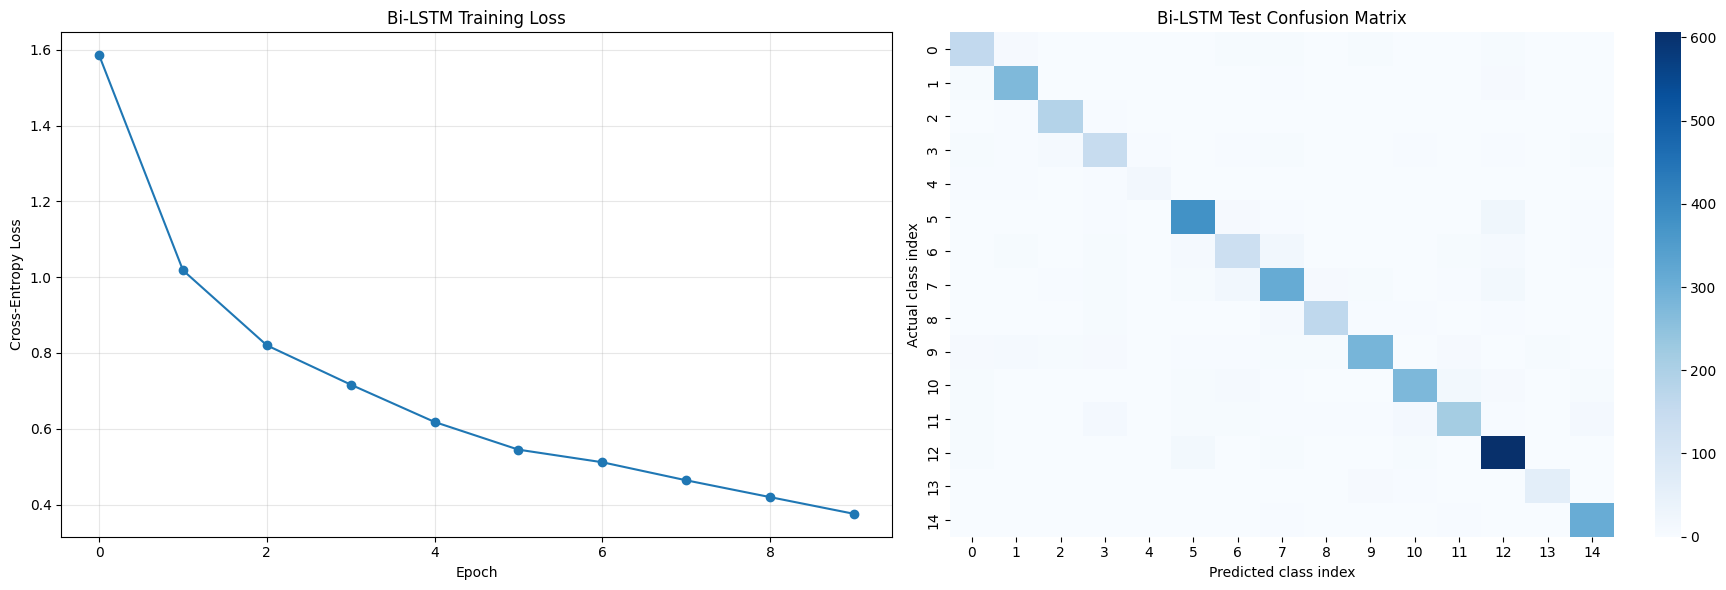

Bi-LSTM Test Accuracy: 85.30%


In [10]:

# Bi-LSTM Model for Plant Disease Classification

class PlantDiseaseBiLSTM(nn.Module):
    def __init__(self, num_classes, hidden_size=128, num_layers=2):
        super(PlantDiseaseBiLSTM, self).__init__()

        self.lstm = nn.LSTM(
            input_size=3 * image_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=0.25
        )

        # Bidirectional output = hidden_size * 2
        self.fc = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(hidden_size * 2, num_classes)
        )

    def forward(self, x):
        # Convert image into row sequences
        x = x.permute(0, 2, 1, 3).contiguous()

        x = x.view(
            x.size(0),
            image_size,
            3 * image_size
        )

        # Bi-LSTM
        out, (hidden, cell) = self.lstm(x)

        # Use final forward and backward hidden states
        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        combined = torch.cat(
            (forward_hidden, backward_hidden),
            dim=1
        )

        output = self.fc(combined)

        return output


# Initialize Bi-LSTM
bilstm_model = PlantDiseaseBiLSTM(num_classes).to(device)

# Train Bi-LSTM
bilstm_model, bilstm_history = train_model(
    bilstm_model,
    train_loader,
    test_loader,
    epochs=10,
    lr=0.001
)

# Evaluate Bi-LSTM
bilstm_acc, bilstm_preds, _ = show_evaluation(
    "Bi-LSTM",
    bilstm_model,
    bilstm_history,
    test_loader
)

print(f"Bi-LSTM Test Accuracy: {bilstm_acc * 100:.2f}%")


l**. RNN model**

Epoch [1/10] Loss: 2.0323 | Train Acc: 32.92% | Test Acc: 41.28%
Epoch [2/10] Loss: 1.7538 | Train Acc: 41.90% | Test Acc: 43.80%
Epoch [3/10] Loss: 1.6268 | Train Acc: 46.35% | Test Acc: 50.87%
Epoch [4/10] Loss: 1.5737 | Train Acc: 48.07% | Test Acc: 41.33%
Epoch [5/10] Loss: 1.5788 | Train Acc: 48.33% | Test Acc: 51.53%
Epoch [6/10] Loss: 1.4751 | Train Acc: 51.48% | Test Acc: 55.43%
Epoch [7/10] Loss: 1.4111 | Train Acc: 54.19% | Test Acc: 54.36%
Epoch [8/10] Loss: 1.3840 | Train Acc: 54.85% | Test Acc: 53.05%
Epoch [9/10] Loss: 1.4235 | Train Acc: 53.23% | Test Acc: 55.31%
Epoch [10/10] Loss: 1.3631 | Train Acc: 55.41% | Test Acc: 56.13%

RNN Test Accuracy: 56.13%
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.50      0.40      0.45       199
                     Pepper__bell___healthy       0.58      0.70      0.63       296
                      Potato___Early_blight       0.46      0.81  

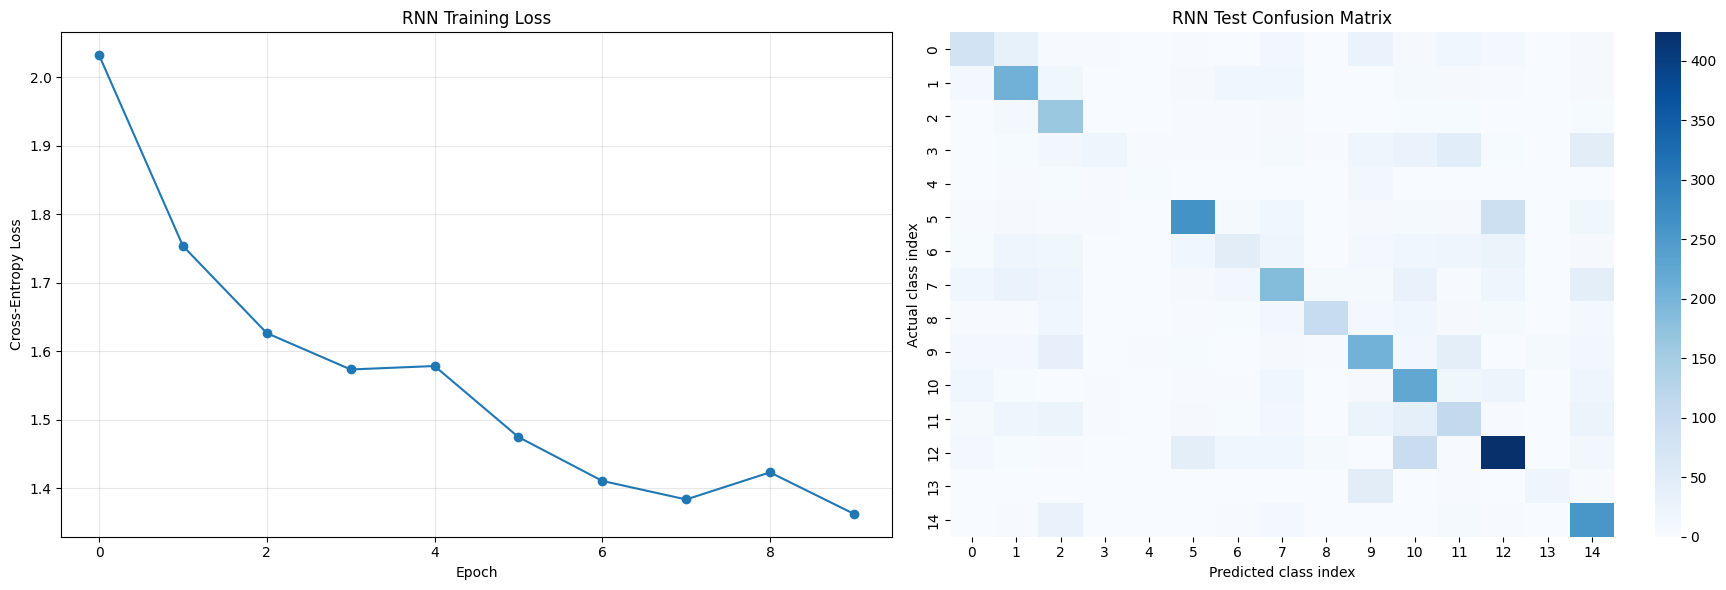

In [5]:
# 5. RNN model: same row-sequence representation as the LSTM
class PlantDiseaseRNN(nn.Module):
    def __init__(self, num_classes, hidden_size=128, num_layers=2):
        super().__init__()
        self.rnn = nn.RNN(input_size=3*image_size, hidden_size=hidden_size,
                          num_layers=num_layers, nonlinearity="tanh",
                          batch_first=True, dropout=0.25)
        self.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(hidden_size, num_classes))
    def forward(self, x):
        x = x.permute(0, 2, 1, 3).contiguous().view(x.size(0), image_size, 3*image_size)
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

rnn_model = PlantDiseaseRNN(num_classes)
rnn_model, rnn_history = train_model(rnn_model, train_loader, test_loader, epochs=10)
rnn_acc, rnn_preds, _ = show_evaluation("RNN", rnn_model, rnn_history, test_loader)

**GNN Model**

Building training graphs...
Building testing graphs...
Epoch [1/10] Loss: 1.5473 | Train Acc: 50.14% | Test Acc: 66.23%
Epoch [2/10] Loss: 0.9781 | Train Acc: 67.61% | Test Acc: 62.31%
Epoch [3/10] Loss: 0.8313 | Train Acc: 72.12% | Test Acc: 75.65%
Epoch [4/10] Loss: 0.7351 | Train Acc: 75.34% | Test Acc: 78.25%
Epoch [5/10] Loss: 0.6793 | Train Acc: 76.98% | Test Acc: 80.18%
Epoch [6/10] Loss: 0.6302 | Train Acc: 79.01% | Test Acc: 74.18%
Epoch [7/10] Loss: 0.5875 | Train Acc: 80.24% | Test Acc: 82.24%
Epoch [8/10] Loss: 0.5685 | Train Acc: 80.96% | Test Acc: 76.77%
Epoch [9/10] Loss: 0.5254 | Train Acc: 82.46% | Test Acc: 86.14%
Epoch [10/10] Loss: 0.5092 | Train Acc: 82.84% | Test Acc: 81.76%

GNN Test Accuracy: 81.76%
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.79      0.70      0.74       199
                     Pepper__bell___healthy       0.77      0.96      0.86       296
           

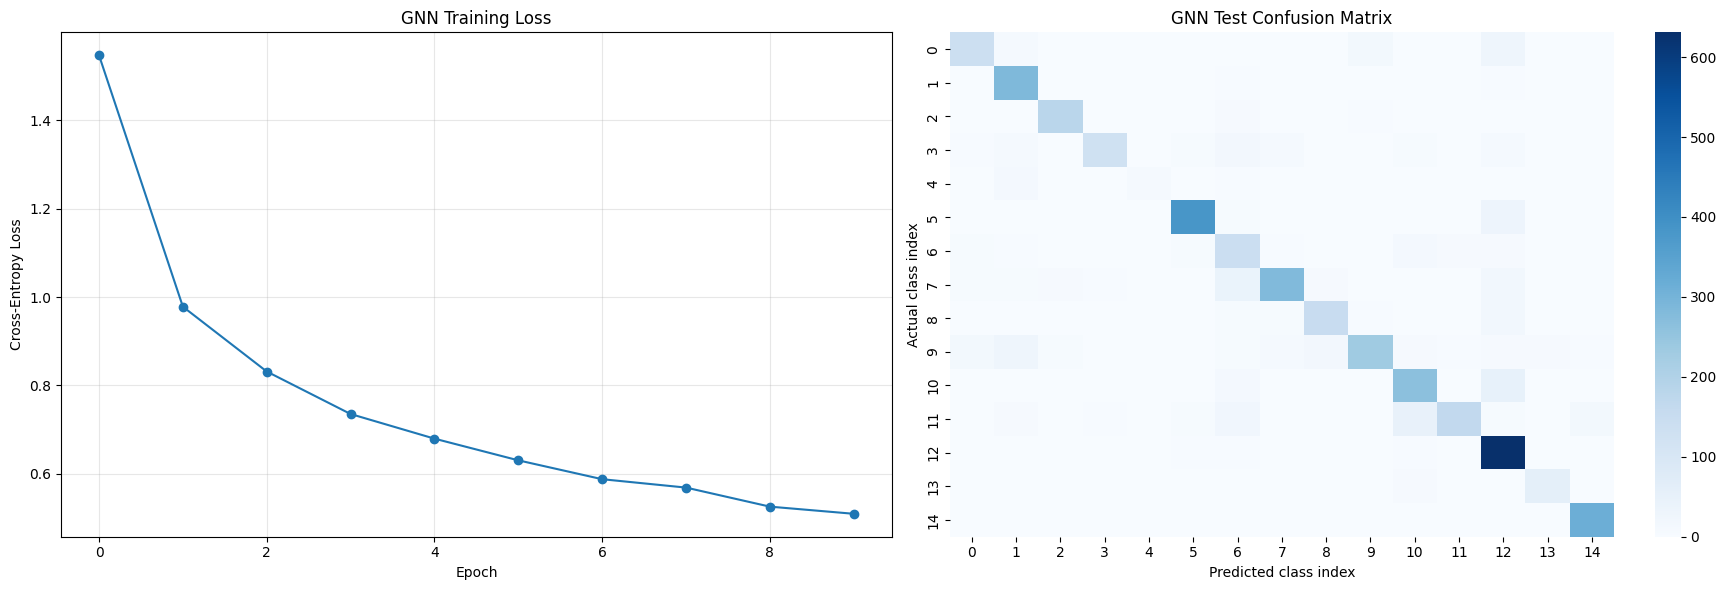

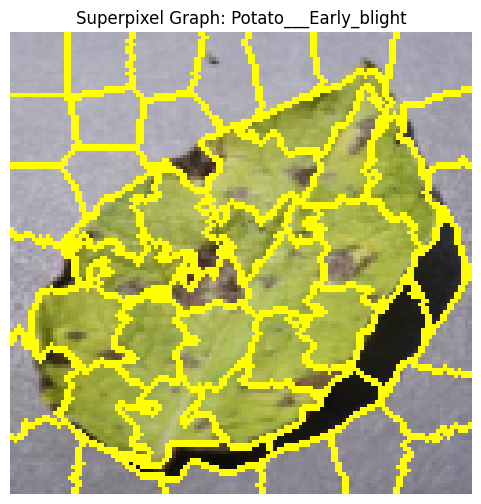

In [7]:

# 6. GNN Model - Plant Disease Classification

from skimage.segmentation import slic, mark_boundaries

N_SEGMENTS = 64

def image_to_graph(image_tensor, n_segments=N_SEGMENTS):
    img = (image_tensor.permute(1, 2, 0).cpu().numpy() * 0.5 + 0.5).clip(0, 1)

    segments = slic(
        img,
        n_segments=n_segments,
        compactness=10,
        channel_axis=-1,
        start_label=0
    )

    n_nodes = min(int(segments.max()) + 1, n_segments)

    # FIXED: 9 node features
    node_features = np.zeros((n_segments, 9), dtype=np.float32)

    h, w, _ = img.shape
    adjacency = np.eye(n_segments, dtype=np.float32)

    for node in range(n_nodes):
        mask = segments == node

        if mask.any():
            pixels = img[mask]
            ys, xs = np.where(mask)

            node_features[node] = np.r_[
                pixels.mean(axis=0),
                pixels.std(axis=0),
                pixels.shape[0] / (h * w),
                ys.mean() / h,
                xs.mean() / w
            ]

    # Create adjacency matrix
    for a, b in [
        (segments[:, :-1], segments[:, 1:]),
        (segments[:-1, :], segments[1:, :])
    ]:
        different = a != b
        pairs = np.stack([a[different], b[different]], axis=1)

        for u, v in pairs:
            if u < n_segments and v < n_segments:
                adjacency[u, v] = 1.0
                adjacency[v, u] = 1.0

    degree = adjacency.sum(axis=1)
    inv_sqrt = np.power(degree, -0.5, where=degree > 0)
    adjacency = inv_sqrt[:, None] * adjacency * inv_sqrt[None, :]

    return (
        torch.tensor(node_features),
        torch.tensor(adjacency, dtype=torch.float32),
        segments
    )


def make_graph_dataset(subset, description):
    graph_x, graph_adj, graph_y = [], [], []

    print("Building", description, "graphs...")

    for i in range(len(subset)):
        image, label = subset[i]

        x, adj, _ = image_to_graph(image)

        graph_x.append(x)
        graph_adj.append(adj)
        graph_y.append(label)

    return TensorDataset(
        torch.stack(graph_x),
        torch.stack(graph_adj),
        torch.tensor(graph_y, dtype=torch.long)
    )


# Create graph datasets
train_graph_data = make_graph_dataset(train_data, "training")
test_graph_data = make_graph_dataset(test_data, "testing")

graph_train_loader = DataLoader(
    train_graph_data, batch_size=32, shuffle=True
)

graph_test_loader = DataLoader(
    test_graph_data, batch_size=32, shuffle=False
)


# GCN Layer
class GCNLayer(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()

        self.linear = nn.Linear(in_features, out_features)
        self.bn = nn.BatchNorm1d(out_features)

    def forward(self, x, adj):
        x = torch.bmm(adj, self.linear(x))
        return self.bn(x.transpose(1, 2)).transpose(1, 2)


# GNN Model
class PlantDiseaseGNN(nn.Module):
    def __init__(self, num_classes, in_features=9, hidden=64):
        super().__init__()

        self.gcn1 = GCNLayer(in_features, hidden)
        self.gcn2 = GCNLayer(hidden, hidden * 2)
        self.gcn3 = GCNLayer(hidden * 2, hidden * 2)

        self.fc = nn.Sequential(
            nn.Linear(hidden * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.35),
            nn.Linear(128, num_classes)
        )

    def forward(self, x, adj):
        x = F.relu(self.gcn1(x, adj))
        x = F.relu(self.gcn2(x, adj))
        x = F.relu(self.gcn3(x, adj))

        x = torch.cat([
            x.mean(1),
            x.max(1).values
        ], dim=1)

        return self.fc(x)


# Train GNN
gnn_model = PlantDiseaseGNN(num_classes).to(device)

gnn_model, gnn_history = train_model(
    gnn_model,
    graph_train_loader,
    graph_test_loader,
    epochs=10,
    graph_model=True
)

# Evaluate GNN
gnn_acc, gnn_preds, _ = show_evaluation(
    "GNN",
    gnn_model,
    gnn_history,
    graph_test_loader,
    graph_model=True
)


# Display superpixel segmentation
sample_image, sample_label = test_data[0]

_, _, sample_segments = image_to_graph(sample_image)

sample_rgb = (
    sample_image.permute(1, 2, 0).numpy() * 0.5 + 0.5
).clip(0, 1)

plt.figure(figsize=(6, 6))
plt.imshow(mark_boundaries(sample_rgb, sample_segments))
plt.title(f"Superpixel Graph: {class_names[sample_label]}")
plt.axis("off")
plt.show()


**Compare model performance using measured test results**

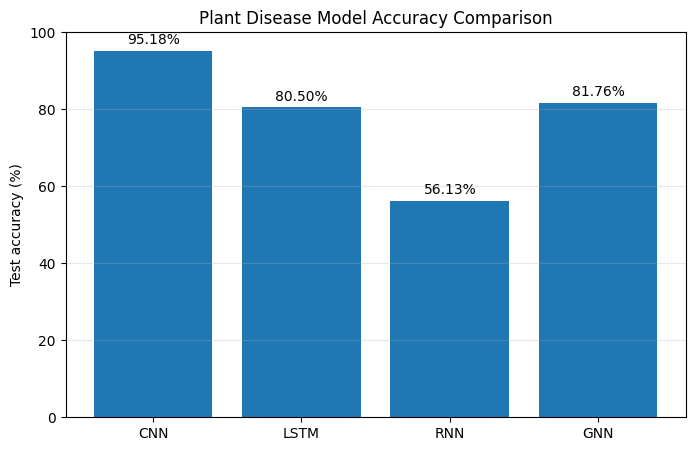

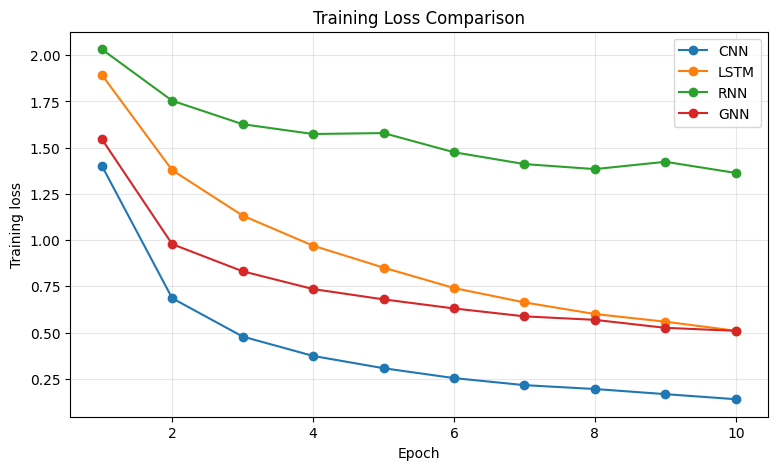

Measured test accuracy:
CNN: 95.18%
LSTM: 80.50%
RNN: 56.13%
GNN: 81.76%


In [8]:
# 7. Compare model performance using measured test results
model_names = ["CNN", "LSTM", "RNN", "GNN"]
accuracies = [cnn_acc, lstm_acc, rnn_acc, gnn_acc]
histories = [cnn_history, lstm_history, rnn_history, gnn_history]

plt.figure(figsize=(8,5))
bars = plt.bar(model_names, [a*100 for a in accuracies])
plt.ylabel("Test accuracy (%)"); plt.title("Plant Disease Model Accuracy Comparison")
plt.ylim(0, 100); plt.grid(axis="y", alpha=0.3)
for bar, value in zip(bars, accuracies):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1, f"{value*100:.2f}%",
             ha="center", va="bottom")
plt.show()

plt.figure(figsize=(9,5))
for name, history in zip(model_names, histories):
    plt.plot(range(1, len(history["loss"])+1), history["loss"], marker="o", label=name)
plt.xlabel("Epoch"); plt.ylabel("Training loss")
plt.title("Training Loss Comparison"); plt.legend(); plt.grid(alpha=0.3); plt.show()

print("Measured test accuracy:")
for name, value in zip(model_names, accuracies):
    print(f"{name}: {value*100:.2f}%")

 Sample CNN predictions 

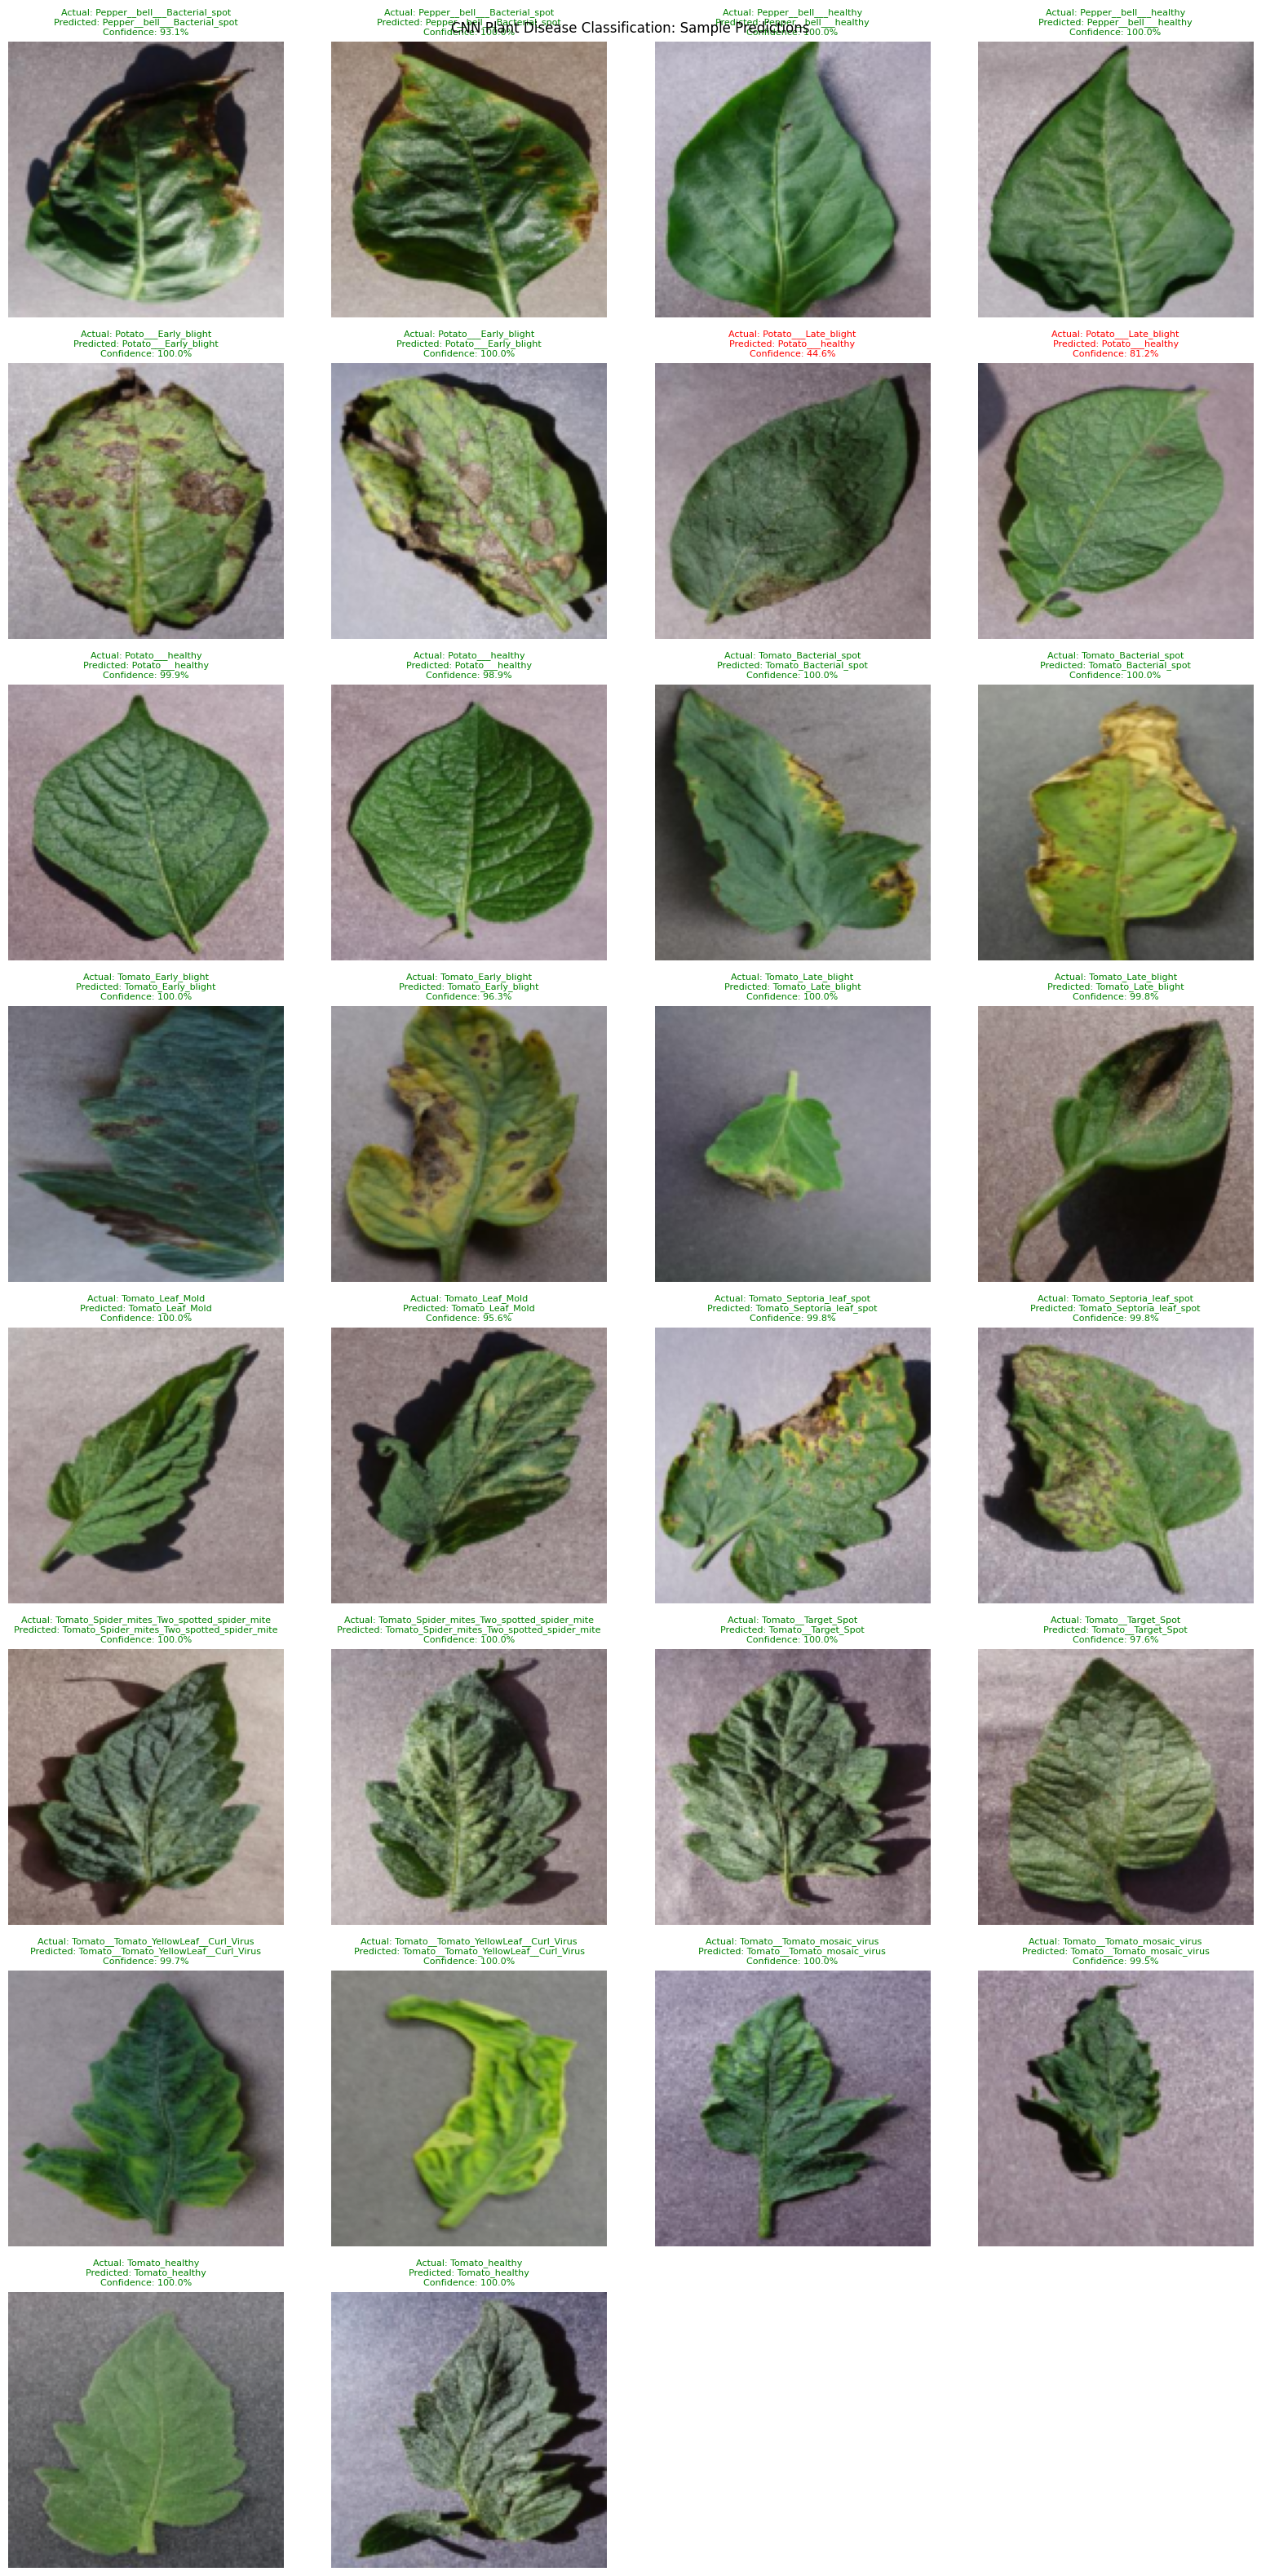

In [9]:
# 8. Sample CNN predictions (two test images per class when available)
import torch.nn.functional as F
class_to_indices = {i: [] for i in range(num_classes)}
for local_idx, original_idx in enumerate(test_idx):
    class_to_indices[int(full_data.targets[original_idx])].append(local_idx)

selected_indices = []
for class_idx in range(num_classes):
    candidates = class_to_indices[class_idx]
    selected_indices.extend(random.sample(candidates, min(2, len(candidates))))

cols = 4
rows = int(np.ceil(len(selected_indices) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(16, 4*rows))
axes = np.array(axes).reshape(-1)
cnn_model.eval()
with torch.no_grad():
    for ax, idx in zip(axes, selected_indices):
        image, actual_idx = test_data[idx]
        logits = cnn_model(image.unsqueeze(0).to(device))
        probabilities = F.softmax(logits, dim=1)
        confidence, predicted_idx = probabilities.max(1)
        rgb = (image.permute(1,2,0).numpy()*0.5+0.5).clip(0,1)
        ax.imshow(rgb); ax.axis("off")
        correct = actual_idx == predicted_idx.item()
        ax.set_title(
            f"Actual: {class_names[actual_idx]}\nPredicted: {class_names[predicted_idx.item()]}\n"
            f"Confidence: {confidence.item()*100:.1f}%",
            color="green" if correct else "red", fontsize=8
        )
for ax in axes[len(selected_indices):]:
    ax.axis("off")
plt.suptitle("CNN Plant Disease Classification: Sample Predictions")
plt.tight_layout(); plt.show()